# What makes a music artist successful?
### Programming for Data Science 2026/2027 · Group Project · Group XX

| Name | Student number |
|---|---|
| Member 1 | 20XXXXXX |
| Member 2 | 20XXXXXX |
| Member 3 | 20XXXXXX |
| Member 4 | 20XXXXXX |

**GitHub repository:** *(add the public link here)*

### <font color='#BFD72F'>Table of Contents</font> <a class="anchor" id='toc'></a>

- [0. Setup and Data Import](#P0)
- [4.1 Data Wrangling and Analysis](#P41)
    - [Q1. Data quality: duplicates, missing values and other issues](#Q1)
    - [Q2. Artists, genres, countries and languages](#Q2)
    - [Q3. Update dates](#Q3)
    - [Q4. Career length and collaborations](#Q4)
    - [Q5. Additional insights](#Q5)
- 4.2 Advanced Topic: Building Interactive Maps *(to do)*
- 4.3 Data Science in Action *(to do)*

### <font color='#BFD72F'>0. Setup and Data Import</font> <a class="anchor" id="P0"></a>
[Back to TOC](#toc)

**Step 0.1:** Import the libraries and show the version of each package (as requested in the project guidelines).

In [1]:
# Install if necessary
#!pip install pandas pyarrow matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter(action = 'ignore', category = FutureWarning)

# Package versions used in this notebook
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('matplotlib:', matplotlib.__version__)
print('seaborn:', sns.__version__)

pandas: 3.0.5
numpy: 2.5.3
matplotlib: 3.11.2
seaborn: 0.13.2


In [2]:
# Global plot style for the whole notebook
sns.set_style('whitegrid')
MAIN_COLOR = '#4CAF50'      # green used for highlights
SECOND_COLOR = '#B0BEC5'    # grey used for context

**Step 0.2:** Import the dataset. The file `artist_streams.csv` must be in the same folder as this notebook.

We keep an untouched copy (`artists_raw`) so that every cleaning decision can be compared with the original data.

In [3]:
artists_raw = pd.read_csv('artist_streams.csv')
artists = artists_raw.copy()   # working copy, the raw data stays untouched

print('Shape:', artists.shape)
artists.head()

Shape: (511, 15)


,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0


## <font color='#BFD72F'>4.1 Data Wrangling and Analysis</font> <a class="anchor" id="P41"></a>

### Q1. Are there duplicates or missing values? Other data quality issues? <a class="anchor" id="Q1"></a>
[Back to TOC](#toc)

**Step 1.1:** General overview of the columns, data types and non-null counts.

In [4]:
artists.info()

<class 'pandas.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist ID              511 non-null    int64  
 1   Artist Name            510 non-null    str    
 2   Sex                    486 non-null    str    
 3   Country of Origin      510 non-null    str    
 4   Primary Language       510 non-null    str    
 5   Primary Genre          510 non-null    str    
 6   Artist Type            510 non-null    str    
 7   Debut Year             510 non-null    float64
 8   Total Streams          505 non-null    float64
 9   Lead Streams           504 non-null    float64
 10  Feature Streams        499 non-null    float64
 11  Solo Streams           506 non-null    float64
 12  Collaborative Streams  509 non-null    float64
 13  Update Date            510 non-null    str    
 14  Year                   510 non-null    float64
dtypes: float64(7), in

In [5]:
artists.describe().T

,count,mean,std,min,25%,50%,75%,max
Artist ID,511.0,249.956947,144.020444,0.0,126.500,251.00,373.50,500.0
Debut Year,510.0,2005.201961,13.359191,1939.0,2001.000,2009.00,2014.00,2023.0
Total Streams,505.0,16792.430891,14771.249974,6972.0,8809.400,11966.90,17738.80,137492.1
Lead Streams,504.0,12167.685516,11833.059565,0.0,6489.750,8756.70,13456.90,126177.3
Feature Streams,499.0,4675.364930,5954.390999,0.0,702.800,2993.20,6096.50,43710.5
Solo Streams,506.0,8348.897628,9600.760173,0.0,2505.925,6472.95,10127.05,113421.5
Collaborative Streams,509.0,8434.201768,9551.041044,0.0,1996.600,6578.10,10929.40,84168.2
Year,510.0,2026.000000,0.000000,2026.0,2026.000,2026.00,2026.00,2026.0


First observations:
- There are 511 rows, but the description says the dataset covers each artist once, so we need to check for duplicates.
- Almost every column has some missing values (non-null count below 511).
- `Debut Year` and `Year` are stored as `float` although they are years (integers).
- `Update Date` is stored as text (`str`) instead of a date.
- `Year` seems to have a single value (std = 0).

#### 1.2 Duplicates

**Step 1.2.1:** Check for rows that are completely repeated.

In [6]:
# duplicated() marks as True every row that is an exact copy of a previous row
print('Fully duplicated rows:', artists.duplicated().sum())

# keep = False shows both the original and the copy
artists[artists.duplicated(keep = False)].sort_values('Artist ID')

Fully duplicated rows: 10


,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
45,45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01 00:00:00,2026.0
46,45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01 00:00:00,2026.0
141,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01 00:00:00,2026.0
142,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01 00:00:00,2026.0
220,218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01 00:00:00,2026.0
221,218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01 00:00:00,2026.0
224,221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01 00:00:00,2026.0
225,221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01 00:00:00,2026.0
267,263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01 00:00:00,2026.0
268,263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01 00:00:00,2026.0


There are **10 rows that are exact copies** of another row (same `Artist ID` and same values in every column). They are the same artist recorded twice, so keeping them would count these artists twice and inflate their streams in any aggregation.

**Decision:** remove the copies and keep only the first occurrence.

In [7]:
artists = artists.drop_duplicates().reset_index(drop = True)

# Confirm that there are no repeated artists left (by ID and by name)
print('Rows after removing duplicates:', artists.shape[0])
print('Repeated Artist IDs:', artists['Artist ID'].duplicated().sum())
print('Repeated Artist Names:', artists['Artist Name'].dropna().duplicated().sum())

Rows after removing duplicates: 501
Repeated Artist IDs: 0
Repeated Artist Names: 0


#### 1.3 Missing values

**Step 1.3.1:** Count missing values per column.

In [8]:
missing = pd.DataFrame({'Missing values': artists.isna().sum(),
                        '% Missing': (artists.isna().mean() * 100).round(2)})
missing[missing['Missing values'] > 0]

,Missing values,% Missing
Artist Name,1,0.20
Sex,23,4.59
Country of Origin,1,0.20
Primary Language,1,0.20
Primary Genre,1,0.20
Artist Type,1,0.20
Debut Year,1,0.20
Total Streams,6,1.20
Lead Streams,7,1.40
Feature Streams,10,2.00


**Step 1.3.2:** Check how many missing values each row has. A row with many missing values is a different problem from a row with only one.

In [9]:
# Number of missing values per row (axis = 1)
artists.isna().sum(axis = 1).value_counts().sort_index()

0     456
1      41
2       3
14      1
Name: count, dtype: int64

In [10]:
# Rows where every column except the ID is empty
empty_rows = artists.drop(columns = 'Artist ID').isna().all(axis = 1)
artists[empty_rows]

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
500,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


One row (`Artist ID` 500) has **no information at all** besides the ID. It cannot be recovered or used in any analysis.

**Decision:** drop this row.

In [11]:
artists = artists[~empty_rows].reset_index(drop = True)
print('Rows after removing the empty row:', artists.shape[0])

Rows after removing the empty row: 500


**Step 1.3.3: `Sex`**. Before deciding how to fill it, check in which type of artist the missing values occur.

In [12]:
# fillna is only used here to show the missing values as a category in the table
pd.crosstab(index = artists['Artist Type'], columns = artists['Sex'].fillna('Missing'))

Sex,Female,Male,Missing
Artist Type,,,
Group,6,99,22
Solo,82,291,0


In [13]:
artists[artists['Sex'].isna()][['Artist Name', 'Artist Type']]

,Artist Name,Artist Type
38,Maroon 5,Group
45,Linkin Park,Group
59,One Direction,Group
89,Disney,Group
91,Red Hot Chili Peppers,Group
94,OneRepublic,Group
140,Fleetwood Mac,Group
155,Black Eyed Peas,Group
214,Cigarettes After Sex,Group
217,Major Lazer,Group


All 22 missing values of `Sex` belong to **groups**; every solo artist has this information. Some of these groups have members of both sexes (e.g. ABBA, Fleetwood Mac, Black Eyed Peas, Paramore), others are all male, and some are not really bands (Disney, League of Legends).

**Decision:** fill with a new category **`Unknown`** instead of the mode (`Male`). Filling with the mode would assign a wrong sex to mixed groups and would bias any comparison between male and female artists. Dropping the rows would lose 22 artists that have complete streaming data.

In [14]:
artists['Sex'] = artists['Sex'].fillna('Unknown')
artists['Sex'].value_counts()

Sex
Male       390
Female      88
Unknown     22
Name: count, dtype: int64

#### 1.4 Consistency of the stream columns

Before filling the missing stream values, we check the two identities given in the project description:
- `Total Streams = Solo Streams + Collaborative Streams`
- `Total Streams = Lead Streams + Feature Streams`

If they hold, a missing value can be **calculated exactly** from the other columns instead of being estimated.

In [15]:
stream_cols = ['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']

# Difference between each decomposition and the total (only rows without missing values)
complete = artists.dropna(subset = stream_cols).copy()
complete['Diff Solo+Collab'] = (complete['Solo Streams'] + complete['Collaborative Streams'] - complete['Total Streams']).round(1)
complete['Diff Lead+Feature'] = (complete['Lead Streams'] + complete['Feature Streams'] - complete['Total Streams']).round(1)
complete['Diff Lead+Feature (%)'] = (complete['Diff Lead+Feature'] / complete['Total Streams'] * 100).round(3)

complete[['Diff Solo+Collab', 'Diff Lead+Feature', 'Diff Lead+Feature (%)']].describe().round(3)

,Diff Solo+Collab,Diff Lead+Feature,Diff Lead+Feature (%)
count,475.0,475.000,475.000
mean,0.0,5.356,0.041
std,0.0,9.405,0.071
min,0.0,-89.200,-0.545
25%,0.0,1.250,0.010
50%,0.0,5.000,0.035
75%,0.0,9.200,0.055
max,0.0,39.200,0.388


In [16]:
# Artists with the largest differences in the Lead + Feature identity
complete.sort_values('Diff Lead+Feature (%)', key = abs, ascending = False)[
    ['Artist Name'] + stream_cols + ['Diff Lead+Feature', 'Diff Lead+Feature (%)']].head()

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Diff Lead+Feature,Diff Lead+Feature (%)
145,Flo Rida,16366.1,14784.2,1492.7,4359.8,12006.3,-89.2,-0.545
405,Jay Wheeler,8282.3,6707.0,1607.4,999.5,7282.8,32.1,0.388
479,Laufey,7286.8,4703.7,2609.5,6083.2,1203.6,26.4,0.362
278,Little Mix,10985.7,0.0,11024.9,6916.9,4068.8,39.2,0.357
473,Tom Odell,7352.6,3894.0,3483.8,6069.3,1283.3,25.2,0.343


- **Solo + Collaborative = Total holds exactly** for every artist.
- **Lead + Feature does not match Total exactly**: in most artists the difference is a few million streams, and in the worst case it is about **0.5% of the total** (e.g. Flo Rida). In some cases Lead Streams is even slightly larger than Total Streams (e.g. Harry Styles). This is most likely because these columns were collected at slightly different moments or rounded differently in the source.

**Decision:** keep the original values (we cannot know which column is the "correct" one, and the differences are negligible for the analysis). We use **Solo + Collaborative** as the reference decomposition of `Total Streams`, since it is exact.

#### 1.5 Filling the missing stream values

**Step 1.5.1:** Check how many stream values are missing per row.

In [17]:
artists[stream_cols].isna().sum(axis = 1).value_counts()

0    475
1     25
Name: count, dtype: int64

Every row has at most **one** missing stream value, so each one can be calculated from the others:

| Missing column | Calculated as |
|---|---|
| Total Streams | Solo + Collaborative (exact identity) |
| Solo Streams | Total − Collaborative |
| Collaborative Streams | Total − Solo |
| Lead Streams | Total − Feature |
| Feature Streams | Total − Lead |

This is better than filling with the mean or the median, because it uses the information of the artist itself. `Total Streams` is filled first, since the other columns depend on it.

In [18]:
# Keep track of which rows had missing streams, to show them after filling
rows_missing_streams = artists[stream_cols].isna().any(axis = 1)

artists['Total Streams'] = artists['Total Streams'].fillna(artists['Solo Streams'] + artists['Collaborative Streams'])
artists['Solo Streams'] = artists['Solo Streams'].fillna(artists['Total Streams'] - artists['Collaborative Streams'])
artists['Collaborative Streams'] = artists['Collaborative Streams'].fillna(artists['Total Streams'] - artists['Solo Streams'])
artists['Lead Streams'] = artists['Lead Streams'].fillna(artists['Total Streams'] - artists['Feature Streams'])
artists['Feature Streams'] = artists['Feature Streams'].fillna(artists['Total Streams'] - artists['Lead Streams'])

artists[rows_missing_streams][['Artist Name'] + stream_cols].head(10)

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
16,Future,53951.5,27879.0,26072.5,12647.5,41304.0
46,Peso Pluma,33179.8,18699.1,14501.2,3938.3,29241.5
56,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
106,Kygo,19707.8,17824.5,1883.3,250.7,19457.1
123,Sean Paul,18203.3,9663.9,8539.4,4460.6,13742.7
130,Bebe Rexha,17440.2,5928.1,11512.1,2784.0,14656.2
140,Fleetwood Mac,16577.5,16577.5,0.0,16567.4,10.1
167,A.R. Rahman,15240.4,10857.5,4397.5,594.9,14645.5
176,ROSALÍA,14558.4,10084.0,4474.4,5316.8,9241.6
183,Panic! At The Disco,14402.3,4417.2,9985.1,13038.0,1364.3


In [19]:
# Because Lead + Feature is not exact, a calculated value could become negative
print('Negative values per column:')
print((artists[stream_cols] < 0).sum())
artists[(artists[stream_cols] < 0).any(axis = 1)][['Artist Name'] + stream_cols]

Negative values per column:
Total Streams            0
Lead Streams             0
Feature Streams          2
Solo Streams             0
Collaborative Streams    0
dtype: int64


,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
56,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
326,Maná,9914.4,9921.1,-6.7,7817.7,2096.7


Two calculated `Feature Streams` values are slightly negative, because `Lead Streams` was already a bit larger than `Total Streams` for these artists (the small inconsistency found in 1.4). A negative number of streams is impossible.

**Decision:** set these values to 0 (`clip(lower = 0)` replaces every value below 0 by 0).

In [20]:
artists['Feature Streams'] = artists['Feature Streams'].clip(lower = 0)

print('Missing values left:', artists.isna().sum().sum())
print('Negative stream values left:', (artists[stream_cols] < 0).sum().sum())

Missing values left: 0
Negative stream values left: 0


#### 1.6 Categorical columns: spelling and consistency

**Step 1.6.1:** Look at every category of the text columns.

In [21]:
for col in ['Primary Genre', 'Country of Origin', 'Primary Language', 'Artist Type', 'Sex']:
    print(f'{col} ({artists[col].nunique()} categories):')
    print(sorted(artists[col].unique()), '\n')

Primary Genre (23 categories):
['Afrobeats', 'Alternative', 'Bachata', "Children's Music", 'Country', 'EDM', 'Filmi', 'Folk', 'Hip-Hop', 'K-Pop', 'Latin', 'Metal', 'Nu Metal', 'Pop', 'R&B', 'Reggae', 'Reggaeton', 'Regional Mexican', 'Rock', 'Sertanjeo', 'Soul', 'Soundtrack', 'Spoken Word'] 

Country of Origin (43 categories):
['Argentina', 'Australia', 'Austria', 'Barbados', 'Belgium', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Cuba', 'DR Congo', 'Denmark', 'Dominican Republic', 'France', 'Germany', 'Guatemala', 'Iceland', 'India', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Mexico', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'Norway', 'Pakistan', 'Panama', 'Philippines', 'Russia', 'Scotland', 'Senegal', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Trinidad and Tobago', 'United Kingdom', 'United States', 'Venezuela'] 

Primary Language (11 categories):
['English', 'French', 'German', 'Hindi', 'Italian', 'Korean', 'Portuguese', 'Punjabi', 'Spanish', 'Tamil', 'Urdu'] 

Two issues were found:
- **`Sertanjeo`** is a typo of **`Sertanejo`** (Brazilian country music).
- **`Scotland`** appears as a country, while England, Wales and Northern Ireland are always recorded as `United Kingdom`. Keeping it separate would split the UK in two when counting artists per country.

In [22]:
artists[artists['Country of Origin'] == 'Scotland'][['Artist Name', 'Country of Origin']]

,Artist Name,Country of Origin
43,Calvin Harris,Scotland
192,Lewis Capaldi,Scotland


In [23]:
artists['Primary Genre'] = artists['Primary Genre'].replace({'Sertanjeo': 'Sertanejo'})
artists['Country of Origin'] = artists['Country of Origin'].replace({'Scotland': 'United Kingdom'})

print(artists['Primary Genre'].isin(['Sertanjeo']).sum(), 'rows with Sertanjeo left')
print(artists['Country of Origin'].isin(['Scotland']).sum(), 'rows with Scotland left')

0 rows with Sertanjeo left
0 rows with Scotland left


Other observations, kept as they are:
- Puerto Rican artists (e.g. Bad Bunny) are recorded as `United States`. Puerto Rico is a US territory, so this is consistent with the dataset's criteria.
- Groups have a `Sex` when all members share it (e.g. BTS = Male, BLACKPINK = Female). This is a choice of the source, not an error.

#### 1.7 Data types and the `Year` column

In [24]:
print(artists['Year'].value_counts())
print(artists['Update Date'].value_counts())

Year
2026.0    500
Name: count, dtype: int64
Update Date
2026-07-01 00:00:00    490
2025-07-01 00:00:00     10
Name: count, dtype: int64


- `Year` (extraction year) has a **single value, 2026**, so it gives no information to distinguish artists. We keep it because it is the reference year to calculate the career length in Q4.
- `Debut Year` and `Year` are converted to integers.
- `Update Date` is converted to a date (`datetime`), so that we can calculate differences between dates in Q3. All times are `00:00:00`, so no information is lost.

In [25]:
artists['Debut Year'] = artists['Debut Year'].astype('int')
artists['Year'] = artists['Year'].astype('int')
artists['Update Date'] = pd.to_datetime(artists['Update Date'])

artists.dtypes

Artist ID                         int64
Artist Name                         str
Sex                                 str
Country of Origin                   str
Primary Language                    str
Primary Genre                       str
Artist Type                         str
Debut Year                        int64
Total Streams                   float64
Lead Streams                    float64
Feature Streams                 float64
Solo Streams                    float64
Collaborative Streams           float64
Update Date              datetime64[us]
Year                              int64
dtype: object

#### 1.8 Outliers and impossible values

In [26]:
artists[['Debut Year'] + stream_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Debut Year,500.0,2005.3,13.3,1939.0,2001.8,2009.0,2014.0,2023.0
Total Streams,500.0,16817.6,14845.2,6972.0,8768.2,11923.2,18020.0,137492.1
Lead Streams,500.0,12141.7,11844.7,0.0,6489.8,8716.4,13456.9,126177.3
Feature Streams,500.0,4681.2,5952.8,0.0,696.5,3005.6,6093.4,43710.5
Solo Streams,500.0,8324.4,9589.0,0.0,2519.8,6473.0,10115.6,113421.5
Collaborative Streams,500.0,8493.2,9612.5,0.0,2015.6,6592.2,11019.6,84168.2


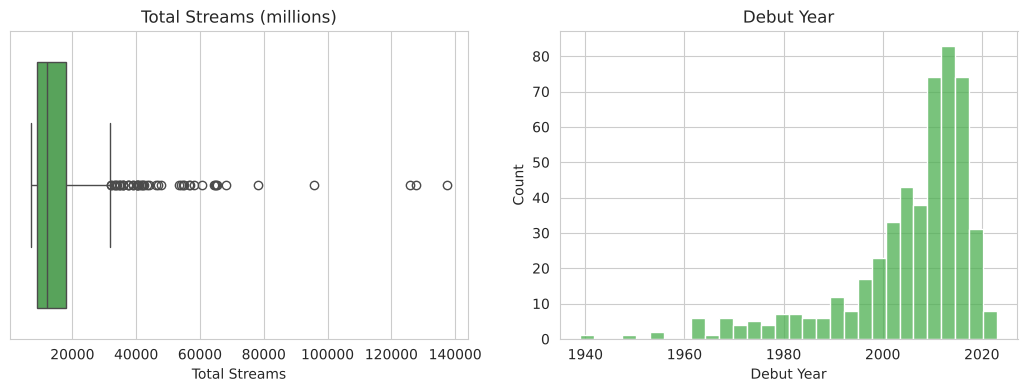

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (13, 4))

sns.boxplot(data = artists, x = 'Total Streams', color = MAIN_COLOR, ax = ax1)
ax1.set_title('Total Streams (millions)')

sns.histplot(data = artists, x = 'Debut Year', bins = 30, color = MAIN_COLOR, ax = ax2)
ax2.set_title('Debut Year')

plt.show()

In [28]:
# The most extreme values on each side
display(artists.nlargest(5, 'Total Streams')[['Artist Name', 'Total Streams']])
display(artists.nsmallest(4, 'Debut Year')[['Artist Name', 'Debut Year']])

,Artist Name,Total Streams
0,Drake,137492.1
1,Taylor Swift,127861.0
2,Bad Bunny,125899.8
3,The Weeknd,95703.2
4,Justin Bieber,78104.4


,Artist Name,Debut Year
240,Frank Sinatra,1939
89,Disney,1949
260,Elvis Presley,1954
465,Johnny Cash,1955


- `Total Streams` is very right skewed: Drake, Taylor Swift and Bad Bunny have more than 125 000 million streams, far above the median (~12 000 million). They are **real values** (the most streamed artists in the world), not errors, so they are kept. Because of them, we will often use the **median** and **logarithmic scales** in the analysis.
- The oldest debut years (Frank Sinatra 1939, Disney 1949, Elvis Presley 1954, Johnny Cash 1955) are historically correct.
- No negative streams and no debut year after the extraction year.

#### 1.9 Summary of the data quality issues

| Issue | Rows affected | Decision | Reason |
|---|---|---|---|
| Fully duplicated rows | 10 | Removed | Same artist counted twice |
| Empty row (only ID) | 1 | Removed | No information to recover |
| Missing `Sex` | 22 (all groups) | New category `Unknown` | Mixed groups; the mode would introduce bias |
| Missing stream values | 25 (max. 1 per row) | Calculated from the stream identities | Exact information from the artist itself |
| Lead + Feature ≠ Total | Most rows, max. 0.5% | Kept; Solo + Collab used as reference | Negligible, source cannot be verified |
| Negative calculated `Feature Streams` | 2 | Set to 0 | Streams cannot be negative |
| Typo `Sertanjeo` | 9 | Corrected to `Sertanejo` | Spelling error |
| `Scotland` vs `United Kingdom` | 2 | Merged into `United Kingdom` | Consistency with the other UK artists |
| Wrong data types | 3 columns | Converted to `int` / `datetime` | Needed for calculations |
| Extreme stream values | Top artists | Kept | Real values; use median / log scale |

In [29]:
print('Final shape:', artists.shape)

# Save the clean dataset, to be reused in sections 4.2 and 4.3
artists.to_csv('artist_streams_clean.csv', index = False)

Final shape: (500, 15)


### Q2. Artists, genres, countries and languages <a class="anchor" id="Q2"></a>
[Back to TOC](#toc)

**a) How many unique artists are in the data? How many pop artists are there?**

In [30]:
n_artists = artists['Artist ID'].nunique()
n_pop = (artists['Primary Genre'] == 'Pop').sum()

print('Unique artists (by ID):', n_artists)
print('Unique artists (by name):', artists['Artist Name'].nunique())
print('Pop artists:', n_pop)

Unique artists (by ID): 500
Unique artists (by name): 500
Pop artists: 102


In [31]:
# Related genres, only for context (they are separate categories in the data)
artists[artists['Primary Genre'].isin(['Pop', 'K-Pop'])]['Primary Genre'].value_counts()

Primary Genre
Pop      102
K-Pop     11
Name: count, dtype: int64

After cleaning, the dataset has **500 unique artists** (the ID and the name agree). **102 artists have `Pop` as their primary genre** (if K-Pop were included as well, there would be 113).

**b) What is the most common primary genre? How many artists are primarily associated with it?**

In [32]:
artists['Primary Genre'].value_counts().head()

Primary Genre
Hip-Hop      115
Pop          102
Rock          60
Reggaeton     43
R&B           31
Name: count, dtype: int64

The most common primary genre is **Hip-Hop, with 115 artists**, just ahead of Pop (102).

**c) What is the most common country of origin? How many artists are from that country?**

In [33]:
artists['Country of Origin'].value_counts().head()

Country of Origin
United States     265
United Kingdom     57
Mexico             27
Canada             18
Colombia           16
Name: count, dtype: int64

In [34]:
print(f"Share of artists from the United States: {(artists['Country of Origin'] == 'United States').mean() * 100:.1f}%")

Share of artists from the United States: 53.0%


The most common country of origin is the **United States, with 265 artists** (53% of the dataset). The second country, the United Kingdom, has only 57.

**d) What are the top 3 most common primary languages? Produce a plot.**

In [35]:
languages = artists['Primary Language'].value_counts()
languages.head(3)

Primary Language
English       340
Spanish       105
Portuguese     15
Name: count, dtype: int64

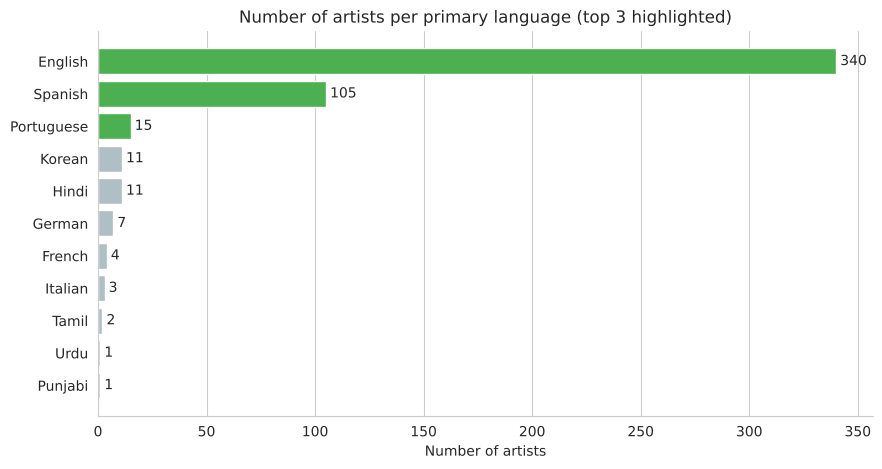

In [36]:
# Top 3 highlighted in green, the remaining languages in grey
colors = [MAIN_COLOR if i < 3 else SECOND_COLOR for i in range(len(languages))]

fig, ax = plt.subplots(figsize = (10, 5))
bars = ax.barh(languages.index, languages.values, color = colors)
ax.bar_label(bars, padding = 3)    # write the count at the end of each bar
ax.invert_yaxis()                  # most common language on top

ax.set_title('Number of artists per primary language (top 3 highlighted)')
ax.set_xlabel('Number of artists')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(False, axis = 'y')
plt.show()

The top 3 primary languages are **English (340 artists), Spanish (105) and Portuguese (15)**. English and Spanish together cover 89% of the artists; every other language has 11 artists or fewer.

### Q3. Update dates <a class="anchor" id="Q3"></a>
[Back to TOC](#toc)

**a) How many days ago were the most recent and oldest updates? On what day, month and year did they occur?**

The number of days depends on the day the notebook is run, so it is calculated with today's date.

In [37]:
today = pd.Timestamp.today().normalize()   # today's date at 00:00

most_recent = artists['Update Date'].max()
oldest = artists['Update Date'].min()

print('Today:', today.date(), '\n')
for label, date in [('Most recent update', most_recent), ('Oldest update', oldest)]:
    print(f'{label}: day {date.day}, {date.month_name()} {date.year}')
    print(f'   -> {(today - date).days} days ago\n')

Today: 2026-10-26 

Most recent update: day 1, July 2026
   -> 117 days ago

Oldest update: day 1, July 2025
   -> 482 days ago



In [38]:
artists['Update Date'].value_counts()

Update Date
2026-07-01    490
2025-07-01     10
Name: count, dtype: int64

- The **most recent update** was on **1 July 2026** (500 − 10 = 490 artists).
- The **oldest update** was on **1 July 2025** (10 artists).

On 26 October 2026 (date of writing) this corresponds to **117 days** and **482 days** ago, respectively. The cell above recalculates these values every time the notebook runs.

**b) Are there artists with out-of-date stream counts (last update before the end of 2025)? Which ones?**

In [39]:
outdated = artists[artists['Update Date'] < '2026-01-01']

print('Artists with out-of-date stream counts:', outdated.shape[0])
outdated[['Artist Name', 'Primary Genre', 'Update Date', 'Total Streams']].sort_values('Total Streams', ascending = False)

Artists with out-of-date stream counts: 10


,Artist Name,Primary Genre,Update Date,Total Streams
109,Quavo,Hip-Hop,2025-07-01,19383.5
175,Gucci Mane,Hip-Hop,2025-07-01,14880.2
193,Grupo Frontera,Regional Mexican,2025-07-01,13999.3
260,Elvis Presley,Rock,2025-07-01,11588.8
353,Teddy Swims,Pop,2025-07-01,9177.5
381,Alejandro Fernández,Latin,2025-07-01,8617.1
387,SEVENTEEN,K-Pop,2025-07-01,8531.3
439,ScHoolboy Q,Hip-Hop,2025-07-01,7817.3
478,Kane Brown,Country,2025-07-01,7313.2
480,Grupo Menos É Mais,Latin,2025-07-01,7277.6


Yes. **10 artists** were last updated on 1 July 2025 and need their stream counts updated: Quavo, Gucci Mane, Grupo Frontera, Elvis Presley, Teddy Swims, Alejandro Fernández, SEVENTEEN, ScHoolboy Q, Grupo Menos É Mais and Kane Brown.

Their totals are one year behind the rest, so they are **underestimated** when compared with the other artists. We keep them in the analysis (they are still valid artists), but this should be remembered when ranking artists by streams.

### Q4. Career length and collaborations <a class="anchor" id="Q4"></a>
[Back to TOC](#toc)

**a) How does the length of an artist's career impact their total streams?**

**Step 4.1:** Create the career length (years between the debut and the extraction year).

In [40]:
artists['Career Length'] = artists['Year'] - artists['Debut Year']
artists['Career Length'].describe().round(1)

count    500.0
mean      20.7
std       13.3
min        3.0
25%       12.0
50%       17.0
75%       24.2
max       87.0
Name: Career Length, dtype: float64

**Step 4.2:** Measure the relationship with a correlation coefficient. Pearson measures a linear relationship and is sensitive to extreme values; Spearman uses the ranks, so it is more robust to the outliers found in 1.8.

In [41]:
print('Pearson correlation: ', round(artists['Career Length'].corr(artists['Total Streams']), 3))
print('Spearman correlation:', round(artists['Career Length'].corr(artists['Total Streams'], method = 'spearman'), 3))

Pearson correlation:  -0.068
Spearman correlation: -0.012


**Step 4.3:** Group the artists into career length brackets, to see whether the relationship changes along the career.

In [42]:
# pd.cut splits a numeric column into intervals (bins)
bins = [0, 5, 10, 15, 20, 30, 100]
labels = ['0-5', '6-10', '11-15', '16-20', '21-30', '30+']
artists['Career Bracket'] = pd.cut(artists['Career Length'], bins = bins, labels = labels)

career_table = artists.groupby('Career Bracket', observed = True)['Total Streams'].agg(['count', 'mean', 'median']).round(1)
career_table

,count,mean,median
Career Bracket,,,
0-5,8,12554.1,9901.8
6-10,76,13033.1,10865.2
11-15,134,19466.5,13479.6
16-20,111,19260.0,12994.4
21-30,90,16580.9,11560.5
30+,81,13323.5,10760.4


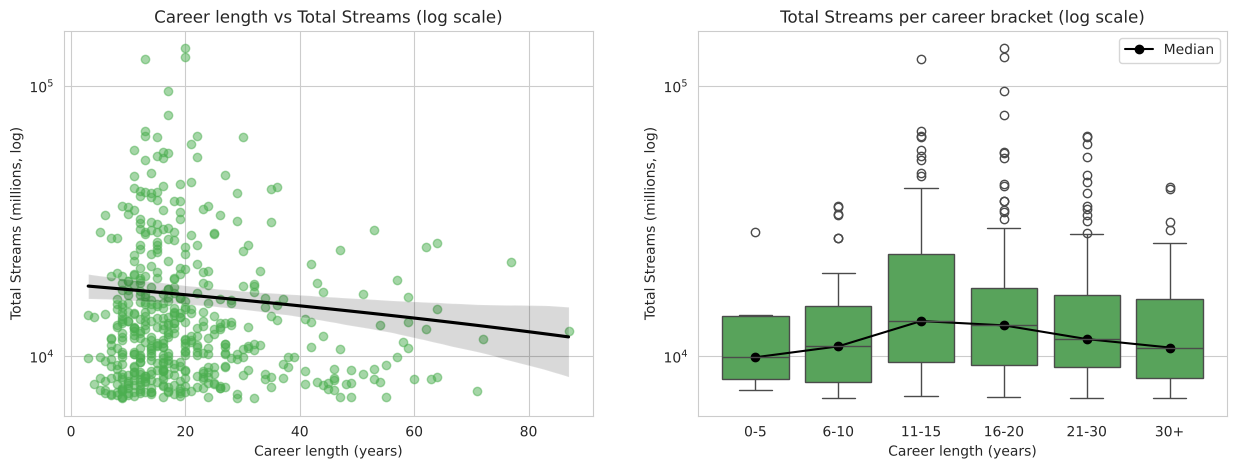

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15, 5))

# Left: every artist, with a regression line
sns.regplot(data = artists, x = 'Career Length', y = 'Total Streams', ax = ax1,
            scatter_kws = {'alpha': 0.5, 'color': MAIN_COLOR}, line_kws = {'color': 'black'})
ax1.set_yscale('log')
ax1.set_title('Career length vs Total Streams (log scale)')
ax1.set_xlabel('Career length (years)')
ax1.set_ylabel('Total Streams (millions, log)')

# Right: distribution per career bracket
sns.boxplot(data = artists, x = 'Career Bracket', y = 'Total Streams', color = MAIN_COLOR, ax = ax2)
ax2.plot(range(len(career_table)), career_table['median'], color = 'black', marker = 'o', label = 'Median')
ax2.set_yscale('log')
ax2.set_title('Total Streams per career bracket (log scale)')
ax2.set_xlabel('Career length (years)')
ax2.set_ylabel('Total Streams (millions, log)')
ax2.legend()

plt.show()

**Conclusions:**
- The correlation between career length and total streams is **practically zero** (Pearson ≈ −0.07, Spearman ≈ −0.01). A longer career does **not** mean more streams.
- The relationship is not linear: artists with **11 to 20 years of career** have the highest median and mean streams. Newer artists (≤10 years) have not had time to accumulate streams, and older artists (30+) built most of their success before streaming existed, so a large part of their audience never streamed their music.
- There is a strong **survivorship effect**: the dataset only includes artists who are already at the top. Newer artists who appear here are the exceptions that grew very fast, which is why they reach levels similar to veterans in fewer years.

**b) Top 5 artists that benefit the most from collaborations (largest % of streams from collaborations)**

In [44]:
artists['% Collaborative'] = (artists['Collaborative Streams'] / artists['Total Streams'] * 100).round(2)
artists['% Solo'] = (artists['Solo Streams'] / artists['Total Streams'] * 100).round(2)

artists.sort_values('% Collaborative', ascending = False)[
    ['Artist Name', 'Primary Genre', 'Total Streams', 'Collaborative Streams', '% Collaborative']].head(10)

,Artist Name,Primary Genre,Total Streams,Collaborative Streams,% Collaborative
447,Kumaar,Pop,7689.5,7689.5,100.00
372,DJ Luian,Reggaeton,8801.6,8801.6,100.00
89,Disney,Soundtrack,22236.1,22236.1,100.00
483,Magenta,Pop,7239.7,7239.7,100.00
277,Irshad Kamil,Filmi,11014.9,11014.9,100.00
246,Amitabh Bhattacharya,Filmi,12136.7,12136.7,100.00
484,Ryan Lewis,Hip-Hop,7237.6,7237.6,100.00
392,Mambo Kingz,Reggaeton,8457.4,8456.1,99.98
63,Pritam,Pop,28543.9,28532.2,99.96
489,benny blanco,Pop,7114.1,7110.2,99.95


Seven artists have **100%** of their streams from collaborations, so the percentage alone does not choose the top 5. As a tie-breaker we use the **absolute number of collaborative streams**: between two artists with 100%, the one with more collaborative streams benefited more from collaborating.

In [45]:
top_collab = artists.sort_values(['% Collaborative', 'Collaborative Streams'], ascending = False)
top5_collab = top_collab.head(5)
top5_collab[['Artist Name', 'Primary Genre', 'Country of Origin', 'Collaborative Streams', '% Collaborative']]

,Artist Name,Primary Genre,Country of Origin,Collaborative Streams,% Collaborative
89,Disney,Soundtrack,United States,22236.1,100.0
246,Amitabh Bhattacharya,Filmi,India,12136.7,100.0
277,Irshad Kamil,Filmi,India,11014.9,100.0
372,DJ Luian,Reggaeton,United States,8801.6,100.0
447,Kumaar,Pop,India,7689.5,100.0


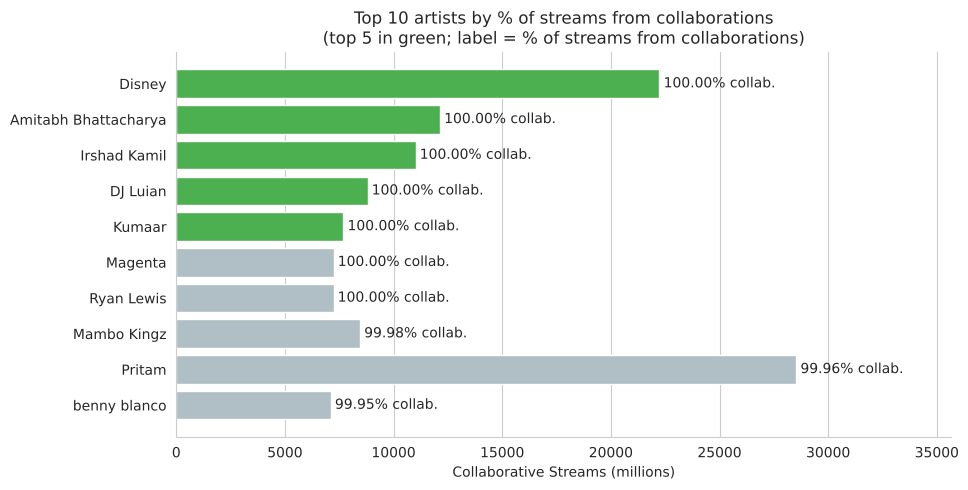

In [46]:
# Top 10 by % collaborative: bar length = collaborative streams (the tie-breaker), top 5 highlighted
top10 = top_collab.head(10).iloc[::-1]   # reversed so that the first artist appears on top
collab_colors = [MAIN_COLOR if name in top5_collab['Artist Name'].values else SECOND_COLOR for name in top10['Artist Name']]

fig, ax = plt.subplots(figsize = (10, 5))
bars = ax.barh(top10['Artist Name'], top10['Collaborative Streams'], color = collab_colors)
ax.bar_label(bars, labels = [f'{p:.2f}% collab.' for p in top10['% Collaborative']], padding = 3)

ax.set_xlim(0, top10['Collaborative Streams'].max() * 1.25)
ax.set_title('Top 10 artists by % of streams from collaborations\n(top 5 in green; label = % of streams from collaborations)')
ax.set_xlabel('Collaborative Streams (millions)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(False, axis = 'y')
plt.show()

The 5 artists that benefit the most from collaborations are **Disney, Amitabh Bhattacharya, Irshad Kamil, DJ Luian and Kumaar**, all with 100% of their streams coming from collaborations.

These are not typical performers: Amitabh Bhattacharya, Irshad Kamil and Kumaar are **Indian lyricists**, DJ Luian is a **reggaeton producer** and Disney is a **soundtrack label**. Their success depends entirely on being credited in songs performed by other artists, which shows that, for some profiles, collaborating is not an extra but the whole business model.

Note: Pritam (Indian film composer) has 99.96% of collaborative streams and the largest volume of the top 10 (~28 500 million). With a slightly less strict criterion (e.g. rounding to one decimal place) he would also enter the top 5.

### Q5. Additional insights <a class="anchor" id="Q5"></a>
[Back to TOC](#toc)

#### Insight 1: Each genre has a very different collaboration profile

Q4b showed that some artists depend completely on collaborations. Here we check whether this is a characteristic of the **genre**. Only genres with at least 10 artists are considered, so that the averages are reliable.

In [47]:
genre_stats = artists.groupby('Primary Genre').agg({'Artist ID': 'count',
                                                    '% Collaborative': 'mean',
                                                    '% Solo': 'mean',
                                                    'Total Streams': 'median'})
genre_stats.columns = ['Artists', '% Collaborative', '% Solo', 'Median Total Streams']

genre_stats = genre_stats[genre_stats['Artists'] >= 10].sort_values('% Collaborative', ascending = False).round(1)
genre_stats

,Artists,% Collaborative,% Solo,Median Total Streams
Primary Genre,,,,
Filmi,11,96.0,4.0,11014.9
EDM,22,87.7,12.3,14694.9
Reggaeton,43,83.6,16.4,12929.7
Hip-Hop,115,66.9,33.1,13692.0
Latin,30,59.3,40.7,9858.3
R&B,31,53.8,46.2,13065.7
Regional Mexican,19,47.0,53.0,12151.3
Pop,102,38.8,61.2,12649.2
Country,10,26.5,73.5,9541.4


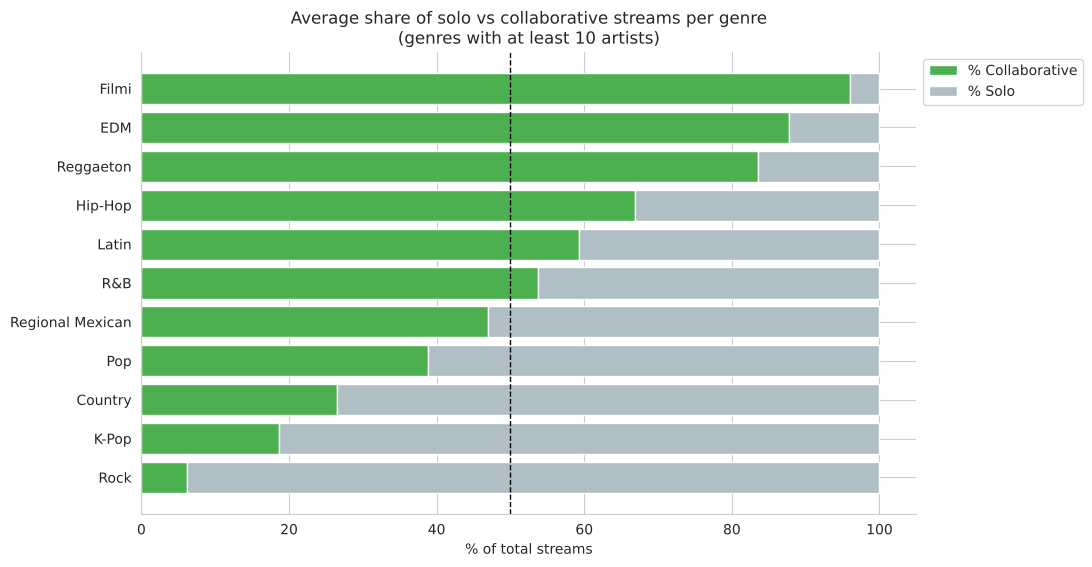

In [48]:
plot_data = genre_stats.iloc[::-1]

fig, ax = plt.subplots(figsize = (10, 6))
ax.barh(plot_data.index, plot_data['% Collaborative'], color = MAIN_COLOR, label = '% Collaborative')
ax.barh(plot_data.index, plot_data['% Solo'], left = plot_data['% Collaborative'], color = SECOND_COLOR, label = '% Solo')
ax.axvline(50, color = 'black', linestyle = '--', linewidth = 1)

ax.set_title('Average share of solo vs collaborative streams per genre\n(genres with at least 10 artists)')
ax.set_xlabel('% of total streams')
ax.legend(loc = 'upper left', bbox_to_anchor = (1, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

- **Filmi (96%), EDM (88%) and Reggaeton (84%)** artists get most of their streams from collaborations. In Filmi, songs are made by teams of composers, lyricists and playback singers; in EDM, producers almost always release songs with a featured vocalist; in Reggaeton, multi-artist songs ("remixes" with several artists) are very common.
- **Rock (6%) and K-Pop (19%)** are the opposite: they are mostly groups that release their own music.
- Pop sits in the middle (39%).

For an artist, the "right" strategy depends on the genre: collaborating is the norm in EDM or Reggaeton, but rare in Rock.

#### Insight 2: Solo artists stream more than groups, and the female "advantage" comes from a few superstars

In [49]:
# Mean vs median by artist type and by sex
display(artists.groupby('Artist Type')['Total Streams'].agg(['count', 'mean', 'median']).round(1))
display(artists.groupby('Sex')['Total Streams'].agg(['count', 'mean', 'median']).round(1))

,count,mean,median
Artist Type,,,
Group,127,13290.1,10607.0
Solo,373,18018.7,12700.7


,count,mean,median
Sex,,,
Female,88,18593.5,12097.2
Male,390,16507.8,11837.7
Unknown,22,15206.4,12236.3


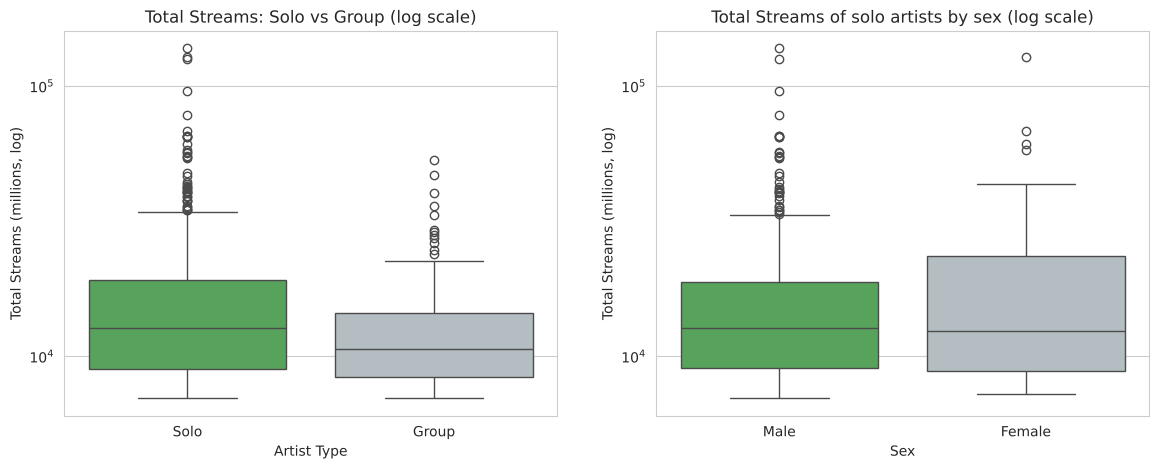

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

sns.boxplot(data = artists, x = 'Artist Type', y = 'Total Streams', hue = 'Artist Type',
            palette = [MAIN_COLOR, SECOND_COLOR], ax = ax1)
ax1.set_yscale('log')
ax1.set_title('Total Streams: Solo vs Group (log scale)')
ax1.set_ylabel('Total Streams (millions, log)')

# Only solo artists, so that the comparison by sex is not mixed with groups
solo = artists[artists['Artist Type'] == 'Solo']
sns.boxplot(data = solo, x = 'Sex', y = 'Total Streams', hue = 'Sex', palette = [MAIN_COLOR, SECOND_COLOR], ax = ax2)
ax2.set_yscale('log')
ax2.set_title('Total Streams of solo artists by sex (log scale)')
ax2.set_ylabel('Total Streams (millions, log)')

plt.show()

In [51]:
# How much does the mean of female artists change without the top 3 female artists?
female = artists[artists['Sex'] == 'Female'].sort_values('Total Streams', ascending = False)
print('Top 3 female artists:', list(female['Artist Name'].head(3)))
print('Mean of female artists:', round(female['Total Streams'].mean(), 1))
print('Mean without the top 3:', round(female['Total Streams'].iloc[3:].mean(), 1))
print('Mean of male artists:  ', round(artists[artists['Sex'] == 'Male']['Total Streams'].mean(), 1))

Top 3 female artists: ['Taylor Swift', 'Ariana Grande', 'Rihanna']
Mean of female artists: 18593.5
Mean without the top 3: 16228.2
Mean of male artists:   16507.8


- **Solo artists** have higher streams than **groups** both in mean and median (median ≈ 12 700 vs 10 600 million). Only 25% of the artists in the top are groups.
- Female artists have a **higher mean** than male artists, but the **medians are almost equal**. The difference is driven by a few superstars (Taylor Swift alone has ~128 000 million streams). Without the top 3 female artists, the female mean drops below the male mean.
- Female artists are only **18%** of the dataset. Reaching the top is harder for women, but those who reach it perform as well as men.

This shows why the **mean can be misleading** in this dataset and why the median is a better summary.

#### Insight 3: English dominates in number of artists, but not in streams per artist

In [52]:
language_stats = artists.groupby('Primary Language').agg({'Artist ID': 'count', 'Total Streams': ['sum', 'median']})
language_stats.columns = ['Artists', 'Total Streams', 'Median Streams']
language_stats['% of artists'] = (language_stats['Artists'] / language_stats['Artists'].sum() * 100).round(1)
language_stats['% of streams'] = (language_stats['Total Streams'] / language_stats['Total Streams'].sum() * 100).round(1)

language_stats = language_stats.sort_values('Artists', ascending = False)
language_stats

,Artists,Total Streams,Median Streams,% of artists,% of streams
Primary Language,,,,,
English,340,6055232.7,12769.65,68.0,72.0
Spanish,105,1679371.1,11566.20,21.0,20.0
Portuguese,15,164439.0,10122.50,3.0,2.0
Korean,11,157338.7,8531.30,2.2,1.9
Hindi,11,157453.1,10165.00,2.2,1.9
German,7,81201.2,8906.90,1.4,1.0
French,4,41569.9,9949.50,0.8,0.5
Italian,3,26576.4,9437.30,0.6,0.3
Tamil,2,30138.2,15069.10,0.4,0.4


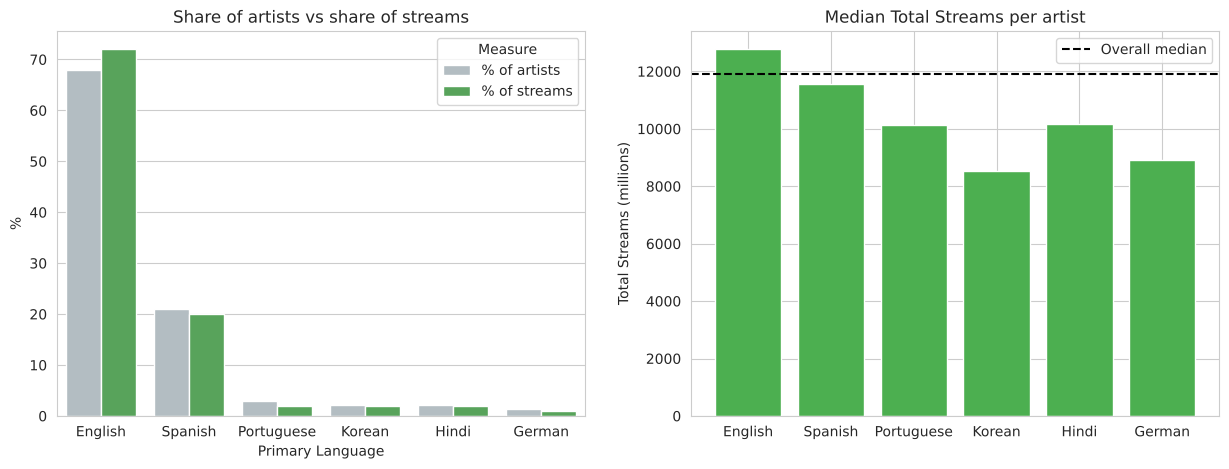

In [53]:
# Languages with at least 7 artists, to keep the medians reliable
main_languages = language_stats[language_stats['Artists'] >= 7]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15, 5))

# Left: share of artists vs share of streams (wide to long, as seen in the Data Wrangling class)
shares = main_languages[['% of artists', '% of streams']].reset_index().melt(
    id_vars = 'Primary Language', var_name = 'Measure', value_name = 'Percentage')
sns.barplot(data = shares, x = 'Primary Language', y = 'Percentage', hue = 'Measure',
            palette = [SECOND_COLOR, MAIN_COLOR], ax = ax1)
ax1.set_title('Share of artists vs share of streams')
ax1.set_ylabel('%')

# Right: median streams per artist
ax2.bar(main_languages.index, main_languages['Median Streams'], color = MAIN_COLOR)
ax2.axhline(artists['Total Streams'].median(), color = 'black', linestyle = '--', label = 'Overall median')
ax2.set_title('Median Total Streams per artist')
ax2.set_ylabel('Total Streams (millions)')
ax2.legend()

plt.show()

- English-language artists are **68% of the artists** and get **72% of the streams**: the share of streams is roughly proportional to the number of artists, so English dominates because there are **more** English-speaking artists, not because each one streams much more.
- **Spanish** is the clear second market (21% of artists, 20% of streams) with a median per artist close to English. Spanish-speaking artists compete at the same level as English-speaking ones.
- Smaller languages (Portuguese, Korean, Hindi, German) have medians below the overall median: these artists reach the top mostly through a strong local market.

[Back to TOC](#toc)